In [1]:
import pandas as pd
from sklearn.naive_bayes import CategoricalNB
from sklearn.preprocessing import LabelEncoder

data = {
    'Age': [
        'Youth', 'Youth', 'Middle', 'Senior', 'Senior', 'Middle', 'Senior',
        'Youth', 'Youth', 'Senior', 'Youth', 'Middle', 'Middle', 'Senior'
    ],
    'Income': [
        'High', 'High', 'High', 'Medium', 'Low', 'Low', 'Low', 'Medium',
        'Low', 'Medium', 'Medium', 'Medium', 'High', 'Medium'
    ],
    'Student': [
        'No', 'No', 'No', 'No', 'Yes', 'Yes', 'Yes', 'No', 'Yes', 'Yes',
        'Yes', 'No', 'Yes', 'No'
    ],
    'CreditRating': [
        'Fair', 'Excellent', 'Fair', 'Fair', 'Fair', 'Excellent', 'Excellent',
        'Fair', 'Fair', 'Fair', 'Excellent', 'Excellent', 'Fair', 'Excellent'
    ],
    'BuysComputer': [
        'No', 'No', 'Yes', 'Yes', 'Yes', 'No', 'Yes', 'No', 'Yes', 'Yes',
        'Yes', 'Yes', 'Yes', 'No'
    ]
}


In [2]:
df = pd.DataFrame(data)


In [3]:
df

,Age,Income,Student,CreditRating,BuysComputer
0,Youth,High,No,Fair,No
1,Youth,High,No,Excellent,No
2,Middle,High,No,Fair,Yes
3,Senior,Medium,No,Fair,Yes
4,Senior,Low,Yes,Fair,Yes
5,Middle,Low,Yes,Excellent,No
6,Senior,Low,Yes,Excellent,Yes
7,Youth,Medium,No,Fair,No
8,Youth,Low,Yes,Fair,Yes
9,Senior,Medium,Yes,Fair,Yes


In [5]:
le = {}
df_enc = df.copy()
for col in df.columns:
    le[col] = LabelEncoder()
    df_enc[col] = le[col].fit_transform(df[col])

In [6]:
df_enc

,Age,Income,Student,CreditRating,BuysComputer
0,2,0,0,1,0
1,2,0,0,0,0
2,0,0,0,1,1
3,1,2,0,1,1
4,1,1,1,1,1
5,0,1,1,0,0
6,1,1,1,0,1
7,2,2,0,1,0
8,2,1,1,1,1
9,1,2,1,1,1


In [8]:
x = df_enc[['Age', 'Income', 'Student', 'CreditRating']]
y = df_enc['BuysComputer']

In [ ]:
# Initialize Categorical Naive Bayes
model = CategoricalNB()

# Train the model
model.fit(x, y)

# Let's predict for a new instance: Age='Youth', Income='Medium', Student='Yes', CreditRating='Fair'
# We need to encode these input features first using the saved LabelEncoders
new_sample = ['Youth', 'Medium', 'Yes', 'Fair']
encoded_sample = []

for val, col in zip(new_sample, ['Age', 'Income', 'Student', 'CreditRating']):
    encoded_val = le[col].transform([val])[0]
    encoded_sample.append(encoded_val)

# Reshape and predict
prediction = model.predict([encoded_sample])
predicted_class = le['BuysComputer'].inverse_transform(prediction)[0]

print(f"Encoded sample: {encoded_sample}")
print(f"Predicted class: {predicted_class}")

In [9]:
x

,Age,Income,Student,CreditRating
0,2,0,0,1
1,2,0,0,0
2,0,0,0,1
3,1,2,0,1
4,1,1,1,1
5,0,1,1,0
6,1,1,1,0
7,2,2,0,1
8,2,1,1,1
9,1,2,1,1


In [10]:
y

,BuysComputer
0,0
1,0
2,1
3,1
4,1
5,0
6,1
7,0
8,1
9,1


In [12]:
test = [['Youth', 'Medium', 'Yes', 'Fair']]

In [13]:
test

[['Youth', 'Medium', 'Yes', 'Fair']]

In [21]:

for t in test:
  row = [
      le['Age'].transform([t[0]])[0],
      le['Income'].transform([t[1]])[0],
      le['Student'].transform([t[2]])[0],
      le['CreditRating'].transform([t[3]])[0]
  ]



  pred = le['BuysComputer'].inverse_transform(model.predict(row))[0]
  prob = model.predict_proba(row)[0]

  print(f'input : Age={t[0]}, Income={t[1]},Student={t[2]},CrediRating={t[3]}')
  print(f'result :buys computer -> {pred}')
  print(f'p(No) = {prob[0]:.4f}')
  print(f'p(Yes) = {prob[1]:.4f}')

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but CategoricalNB was fitted with feature names
  warnings.warn(


ValueError: Expected 2D array, got 1D array instead:
array=[2 2 1 1].
Reshape your data either using array.reshape(-1, 1) if your data has a single feature or array.reshape(1, -1) if it contains a single sample.

In [23]:
from sklearn.metrics import accuracy_score
x_pred = model.predict(x)
print(f'Training accuracy: {accuracy_score(y, x_pred) * 100:.2f}%')

Training accuracy: 78.57%


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but CategoricalNB was fitted with feature names
  warnings.warn(


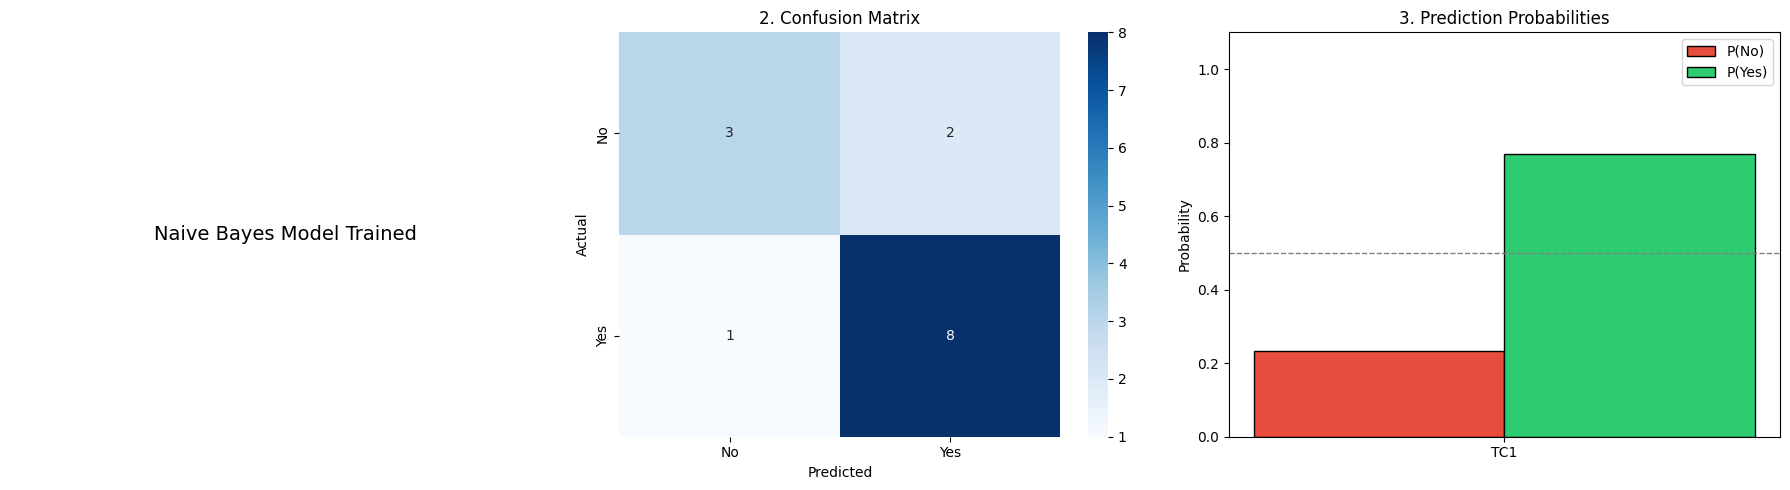

In [25]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import pandas as pd
from sklearn.metrics import confusion_matrix

# Initialize a figure with subplots (1 row, 3 columns)
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. (Optional placeholder for axes[0] to avoid empty subplot)
axes[0].text(0.5, 0.5, 'Naive Bayes Model Trained', ha='center', va='center', fontsize=14)
axes[0].axis('off')

# 2. Confusion Matrix
cm = confusion_matrix(y, model.predict(x))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['No', 'Yes'], yticklabels=['No', 'Yes'], ax=axes[1])
axes[1].set_title("2. Confusion Matrix")
axes[1].set_xlabel("Predicted")
axes[1].set_ylabel("Actual")

# 3. Prediction Probabilities (Grouped Bar)
test_cases = test
probs_no = []
probs_yes = []
feature_cols = ['Age', 'Income', 'Student', 'CreditRating']

for t in test_cases:
    row = [
        le['Age'].transform([t[0]])[0],
        le['Income'].transform([t[1]])[0],
        le['Student'].transform([t[2]])[0],
        le['CreditRating'].transform([t[3]])[0]
    ]
    # Convert to DataFrame with matching feature names to avoid warnings
    row_df = pd.DataFrame([row], columns=feature_cols)

    prob = model.predict_proba(row_df)[0]
    probs_no.append(prob[0])
    probs_yes.append(prob[1])

tc_labels = [f"TC{i+1}" for i in range(len(test_cases))]
x_axis = np.arange(len(tc_labels))
w = 0.3

axes[2].bar(x_axis - w/2, probs_no, w, label='P(No)', color='#e74c3c', edgecolor='black')
axes[2].bar(x_axis + w/2, probs_yes, w, label='P(Yes)', color='#2ecc71', edgecolor='black')
axes[2].axhline(0.5, color='gray', linestyle='--', linewidth=1)
axes[2].set_title("3. Prediction Probabilities")
axes[2].set_xticks(x_axis)
axes[2].set_xticklabels(tc_labels)
axes[2].set_ylabel("Probability")
axes[2].set_ylim(0, 1.1)
axes[2].legend()

plt.tight_layout()
plt.show()

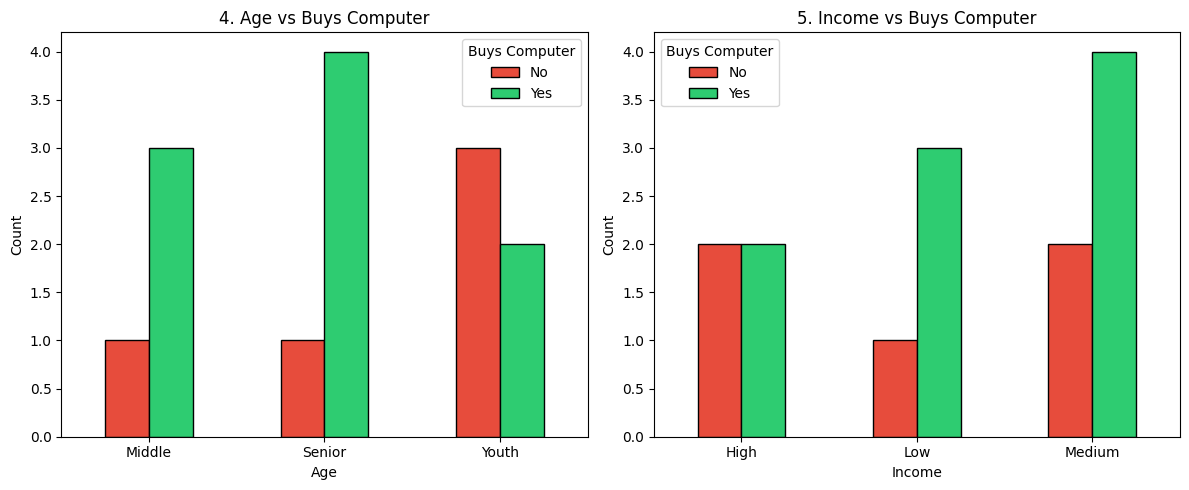

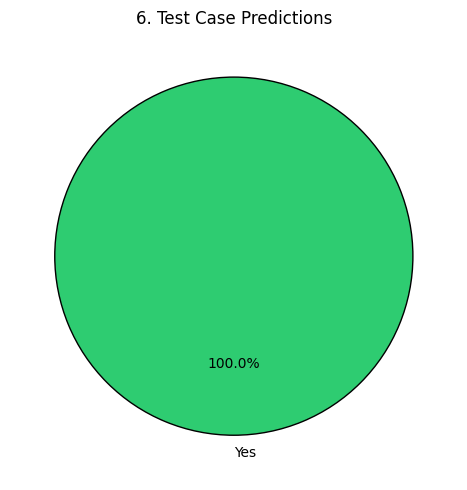

In [32]:
import matplotlib.pyplot as plt
import pandas as pd

# Create a new figure for these two demographic count plots
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# 4. Age vs BuysComputer
age_counts = df.groupby(['Age', 'BuysComputer']).size().unstack(fill_value=0)
age_counts.plot(kind='bar', ax=axes[0], color=['#e74c3c', '#2ecc71'],
                edgecolor='black', rot=0)
axes[0].set_title("4. Age vs Buys Computer")
axes[0].set_xlabel("Age")
axes[0].set_ylabel("Count")
axes[0].legend(title="Buys Computer")

# 5. Income vs BuysComputer
inc_counts = df.groupby(['Income', 'BuysComputer']).size().unstack(fill_value=0)
inc_counts.plot(kind='bar', ax=axes[1], color=['#e74c3c', '#2ecc71'],
                edgecolor='black', rot=0)
axes[1].set_title("5. Income vs Buys Computer")
axes[1].set_xlabel("Income")
axes[1].set_ylabel("Count")
axes[1].legend(title="Buys Computer")

plt.tight_layout()
plt.show()

# 6. Pie Chart - Final Predictions
predictions = []
for t in test:
    row = [
        le['Age'].transform([t[0]])[0],
        le['Income'].transform([t[1]])[0],
        le['Student'].transform([t[2]])[0],
        le['CreditRating'].transform([t[3]])[0]
    ]
    row_df = pd.DataFrame([row], columns=['Age', 'Income', 'Student', 'CreditRating'])
    pred_encoded = model.predict(row_df)[0]
    pred_decoded = le['BuysComputer'].inverse_transform([pred_encoded])[0]
    predictions.append(pred_decoded)

pred_counts = pd.Series(predictions).value_counts()
colors_pie = ['#2ecc71' if val == 'Yes' else '#e74c3c' for val in pred_counts.index]

plt.figure(figsize=(6, 5))
plt.pie(
    pred_counts.values,
    labels=pred_counts.index,
    autopct='%1.1f%%',
    colors=colors_pie,
    startangle=90,
    wedgeprops={'edgecolor': 'black'}
)
plt.title("6. Test Case Predictions")
plt.tight_layout()
plt.show()